# Manual Error Analysis

In each fold, one record causes most of the errors. In folds 3-5, almost all of the errors are attributed to a single record. 

Fold 1 - 08378: 48% of the fold's errors

Fold 2 - 06995, 07859: 55%, 39% of the fold's errors

Fold 3 - 08215: 96% of the fold's errors

Fold 4 - 04936: 86% of the fold's errors

Fold 5 - 07162: 98% of the fold's errors

For records 08215 and 07859, the authors stored the second ECG lead as channel 0. The model training only ever sees channel 0, so on these records, it sees a lead with a different shape from most of the training data. 

## Setup

In [1]:
import json, sys
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BGM = "/Users/tristanmartin/Desktop/IIB PROJECT/BGM_GitHub"
sys.path.insert(0, BGM)
from data.dataset import AFDataset

DATA   = f"{BGM}/afdb_dataset/data"
SPLITS = f"{BGM}/preprocess/data_split/bihaf"
RES    = f"{BGM}/new_runs/results"
FS = 250
LABELS = {0: "N", 1: "AF"}

# Channel 0 set to the second ECG lead
SWAPPED = {"04746", "04908", "05091", "07859", "07879", "07910", "08215", "08219", "08434"}

## Load predictions

`test_predictions.csv` has no record IDs, but its rows follow the loader order: the records in `fold_N.json["val"]` (the AFDB test split), concatenated, with `shuffle=False`.

In [2]:
def load_fold(fold, run = "authcopy"):
    records = json.load(open(f"{SPLITS}/fold_{fold}.json"))["val"]
    rows = []
    for rec in records:
        z = np.load(f"{DATA}/{rec}.npz")
        labels = z["labels"]
        if len(labels) == 0:
            continue
        for i, lab in enumerate(labels):
            rows.append((rec, i, int(lab == "AFIB")))

    meta = pd.DataFrame(rows, columns = ["rec", "win", "y"])

    predictions = pd.read_csv(f"{RES}/bgm_afdb_{fold}_{run}/test_predictions.csv")
    assert len(predictions) == len(meta) and (predictions["label"].values == meta["y"].values).all()

    df = pd.concat([meta, predictions[["prediction", "prob_class_1"]]], axis = 1)
    df = df.rename(columns = {"prediction": "pred", "prob_class_1": "p_af"})
    df["err"] = df["y"] != df["pred"]

    return df

folds = {f: load_fold(f) for f in range(1, 6)}

## Errors per record

In [3]:
def record_errors(df):
    df = df.assign(FN = df["err"] & (df["y"] == 1), FP = df["err"] & (df["y"] == 0))
    g = df.groupby("rec").agg(n = ("y", "size"), af = ("y", "sum"), err = ("err", "sum"),
                              FN = ("FN", "sum"), FP = ("FP", "sum"),
                              median_p_af_err = ("p_af", lambda p: p[df.loc[p.index, "err"]].median()))
    g["err_rate"] = (g["err"] / g["n"]).round(3)
    g["share"] = (g["err"] / g["err"].sum()).round(2)
    g["swapped"] = g.index.isin(SWAPPED)
    return g.sort_values("err", ascending = False)

worst = {}
for f, df in folds.items():
    g = record_errors(df)
    worst[f] = g.index[0]
    print(f"\n=== Fold {f}: {df['err'].sum()} / {len(df)} errors, worst = {worst[f]}")
    display(g)


=== Fold 1: 88 / 12186 errors, worst = 08378


,n,af,err,FN,FP,median_p_af_err,err_rate,share,swapped
rec,,,,,,,,,
08378,1610,108,42,32,10,0.406386,0.026,0.48,False
08405,3583,2561,21,3,18,0.758985,0.006,0.24,False
06453,106,1,16,1,15,0.859803,0.151,0.18,False
08434,3657,124,6,2,4,0.811332,0.002,0.07,True
07879,3230,1786,3,3,0,0.403452,0.001,0.03,True



=== Fold 2: 2626 / 14216 errors, worst = 06995


,n,af,err,FN,FP,median_p_af_err,err_rate,share,swapped
rec,,,,,,,,,
06995,3664,1722,1437,24,1413,0.962983,0.392,0.55,False
07859,3506,3506,1036,1036,0,0.152354,0.295,0.39,True
04015,3382,0,129,0,129,0.802109,0.038,0.05,False
05121,72,28,21,16,5,0.179052,0.292,0.01,False
05261,3592,31,3,0,3,0.810022,0.001,0.00,False



=== Fold 3: 2200 / 12774 errors, worst = 08215


,n,af,err,FN,FP,median_p_af_err,err_rate,share,swapped
rec,,,,,,,,,
08215,3652,2944,2104,2104,0,0.025004,0.576,0.96,True
08219,2974,408,49,40,9,0.008570,0.016,0.02,True
07910,3624,580,32,5,27,0.773991,0.009,0.01,True
04746,2425,913,11,0,11,0.849503,0.005,0.00,True
06426,99,83,4,4,0,0.326845,0.040,0.00,False



=== Fold 4: 612 / 7295 errors, worst = 04936


,n,af,err,FN,FP,median_p_af_err,err_rate,share,swapped
rec,,,,,,,,,
04936,3216,2563,529,522,7,0.129234,0.164,0.86,False
04126,3498,41,40,2,38,0.780295,0.011,0.07,False
04048,267,2,34,1,33,0.577693,0.127,0.06,False
04043,314,219,9,1,8,0.989535,0.029,0.01,False



=== Fold 5: 1238 / 12300 errors, worst = 07162


,n,af,err,FN,FP,median_p_af_err,err_rate,share,swapped
rec,,,,,,,,,
07162,2256,2256,1218,1218,0,0.121271,0.540,0.98,False
08455,2975,1947,11,11,0,0.093130,0.004,0.01,False
04908,3561,229,7,7,0,0.231636,0.002,0.01,True
05091,3508,1,2,0,2,0.849937,0.001,0.00,True


## Plotting functions

In [4]:
@lru_cache(maxsize = 4)
def load_segments(rec):
    # Each record is ~146 MB compressed, so keep only a few in memory
    return np.load(f"{DATA}/{rec}.npz")["segments"]


def plot_windows(df, rec, wins):
    """ch0 (what the model sees), ch1, and the model's STFT image for each window."""
    segs = load_segments(rec)
    t = np.arange(segs.shape[1]) / FS
    fig, axes = plt.subplots(len(wins), 3, figsize = (16, 2.6 * len(wins)),
                             gridspec_kw = {"width_ratios": [4, 4, 1.3]}, squeeze = False)
    for ax, w in zip(axes, wins):
        r = df[(df["rec"] == rec) & (df["win"] == w)].iloc[0]
        seg = segs[w]
        ax[0].plot(t, seg[:, 0], lw = 0.7)
        ax[0].set_ylabel("ch0 (input)")
        ax[1].plot(t, seg[:, 1], lw = 0.7, color = "tab:gray")
        ax[1].set_ylabel("ch1")
        ax[2].imshow(AFDataset._generate_image(None, seg), origin = "lower", aspect = "auto")
        ax[2].set_xticks([])
        ax[2].set_yticks([])
        ax[0].set_title(f"{rec} win {w} ({w * 10 / 60:.1f} min) | true {LABELS[r.y]} -> pred {LABELS[r.pred]} "
                        f"| P(AF) = {r.p_af:.2f}", color = "red" if r.err else "green", loc = "left")
    for a in axes[-1, :2]:
        a.set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()


def plot_timeline(df, rec):
    """P(AF) per window across the record, with the true label and errors marked."""
    d = df[df["rec"] == rec]
    fig, ax = plt.subplots(figsize = (16, 3))
    ax.fill_between(d["win"], 0, d["y"], step = "mid", color = "tab:orange", alpha = 0.25, label = "true AF")
    ax.plot(d["win"], d["p_af"], lw = 0.6, color = "tab:blue", label = "P(AF)")
    ax.scatter(d.loc[d["err"], "win"], d.loc[d["err"], "p_af"], s = 6, color = "red", label = "error", zorder = 3)
    ax.axhline(0.5, ls = "--", color = "k", lw = 0.5)
    ax.set(xlabel = "Window index (10 s each)", ylabel = "P(AF)", ylim = (-0.02, 1.02),
           title = f"{rec}: {d['err'].sum()} / {len(d)} wrong" + (" [channels swapped]" if rec in SWAPPED else ""))
    ax.legend(loc = "upper right", fontsize = 8)
    plt.show()


def error_runs(df, rec, top = 3):
    """Longest stretches of consecutive misclassified windows: (first, last, length)."""
    e = df.loc[(df["rec"] == rec) & df["err"], "win"].values
    if len(e) == 0:
        return []
    runs = np.split(e, np.where(np.diff(e) > 1)[0] + 1)
    runs = sorted(runs, key = len, reverse = True)[:top]
    return [(int(r[0]), int(r[-1]), len(r)) for r in runs]

## Worst record in each fold

For each fold: the P(AF) timeline, three misclassified windows, and two correctly classified windows of the same true class from the same record for comparison.


######## Fold 1: 08378 ########
Longest error runs (first, last, length): [(202, 205, 4), (584, 587, 4), (198, 200, 3)]


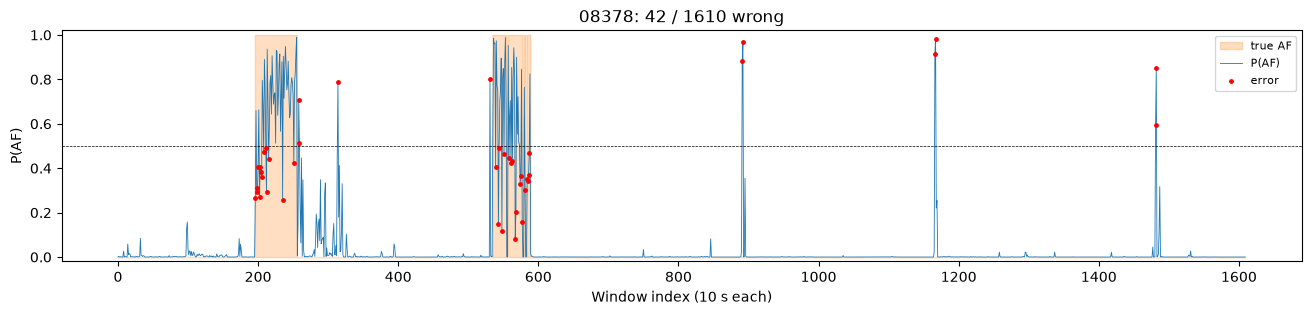

Misclassified:


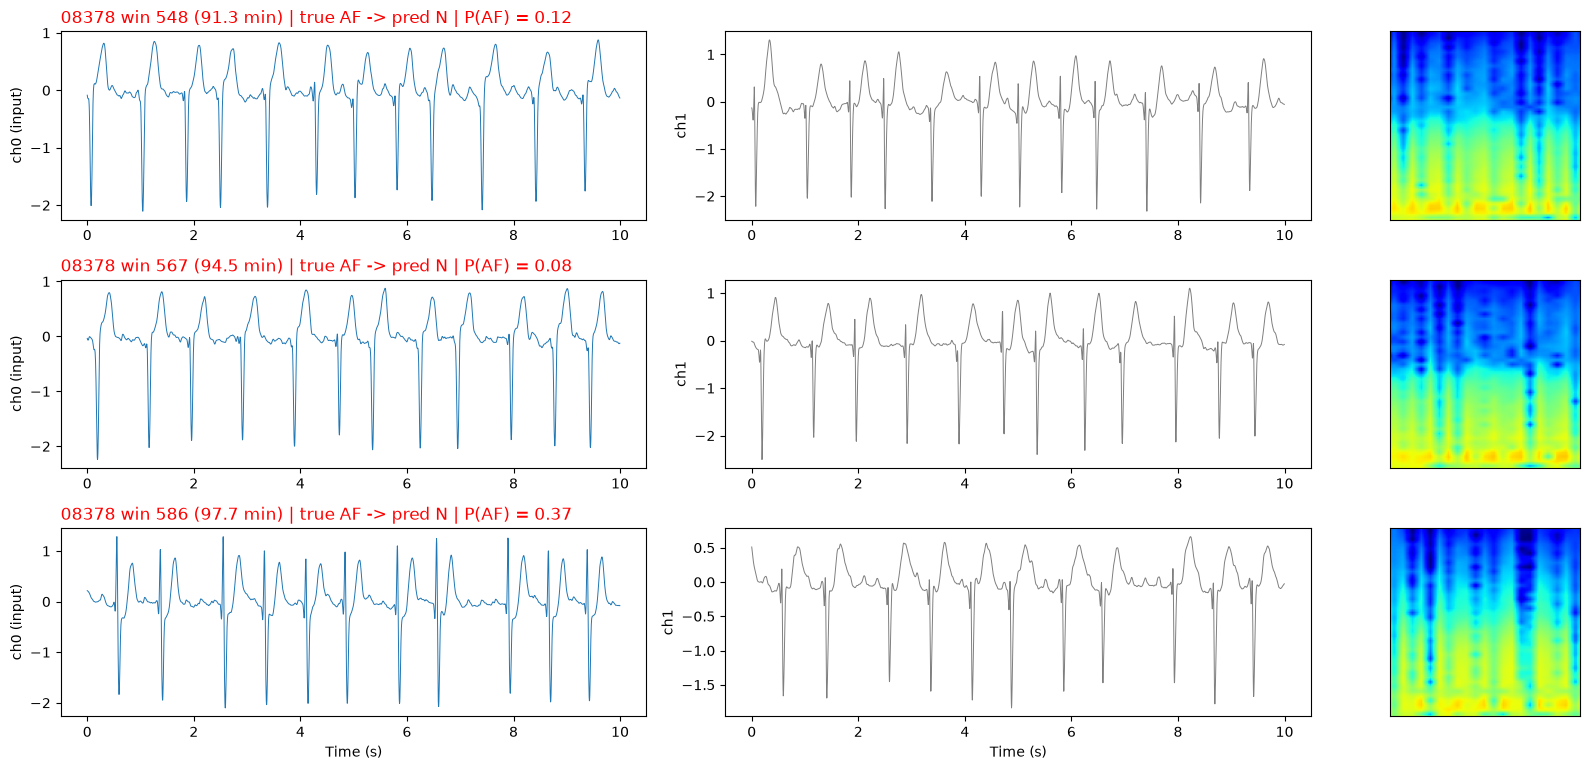

Correct, same true class:


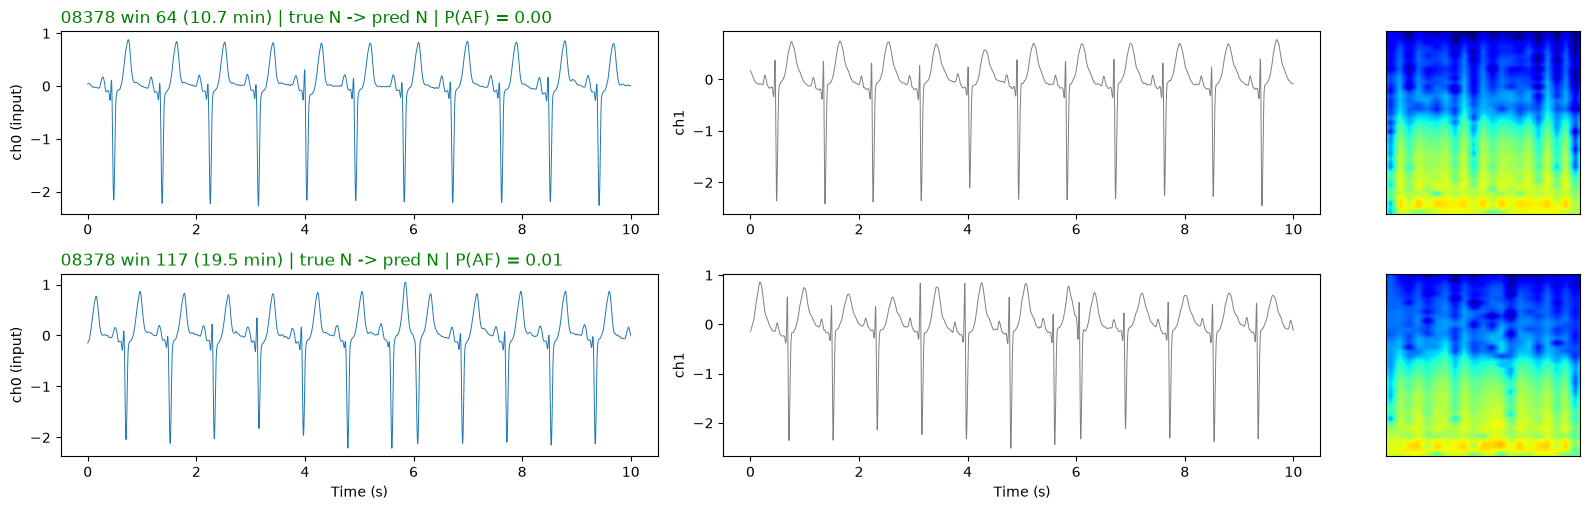


######## Fold 2: 06995 ########
Longest error runs (first, last, length): [(2274, 2354, 81), (1859, 1931, 73), (2017, 2088, 72)]


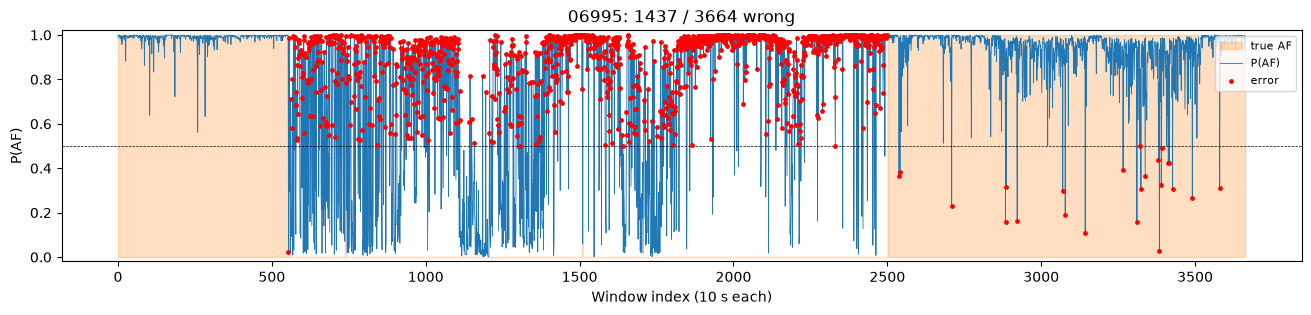

Misclassified:


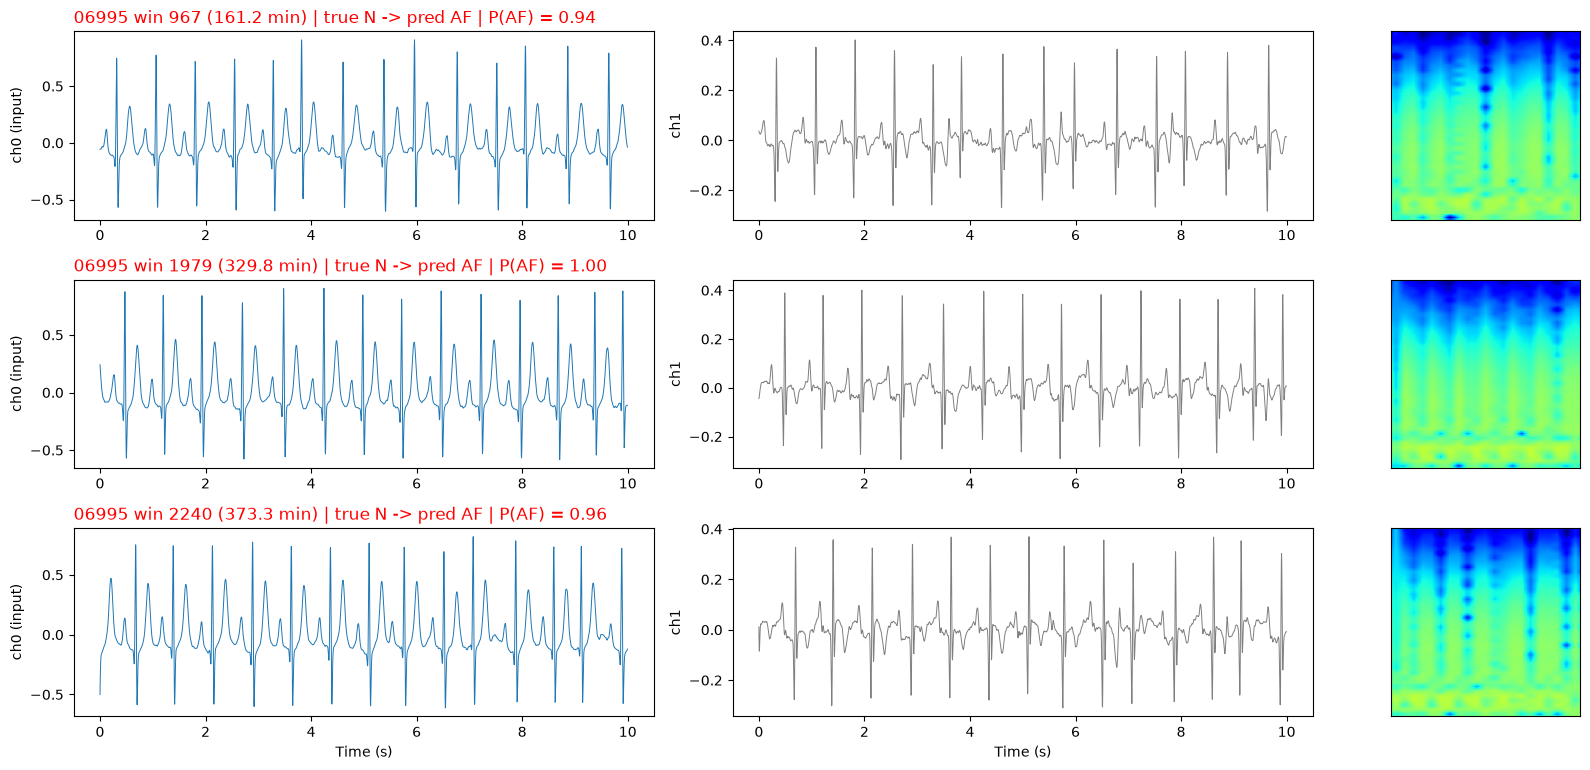

Correct, same true class:


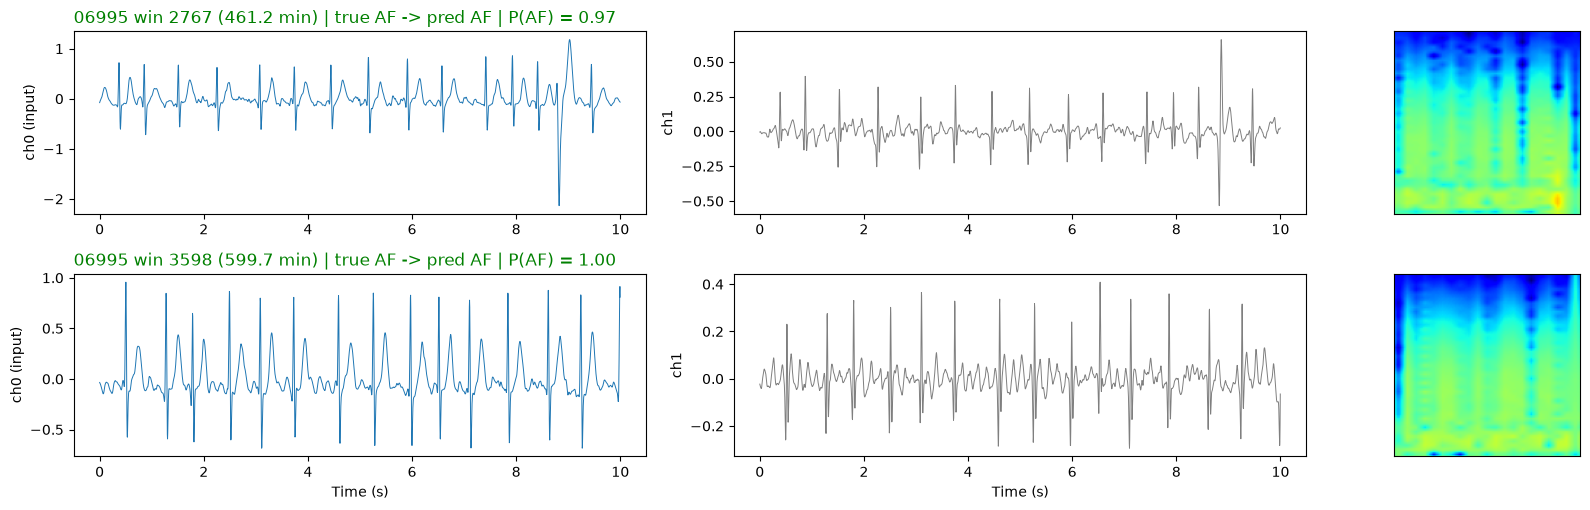


######## Fold 3: 08215 ########
Longest error runs (first, last, length): [(2366, 2455, 90), (3127, 3208, 82), (2173, 2241, 69)]


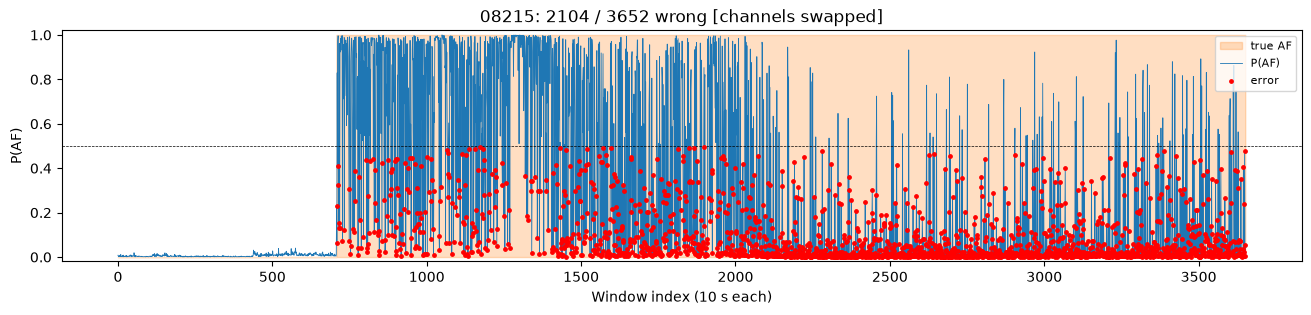

Misclassified:


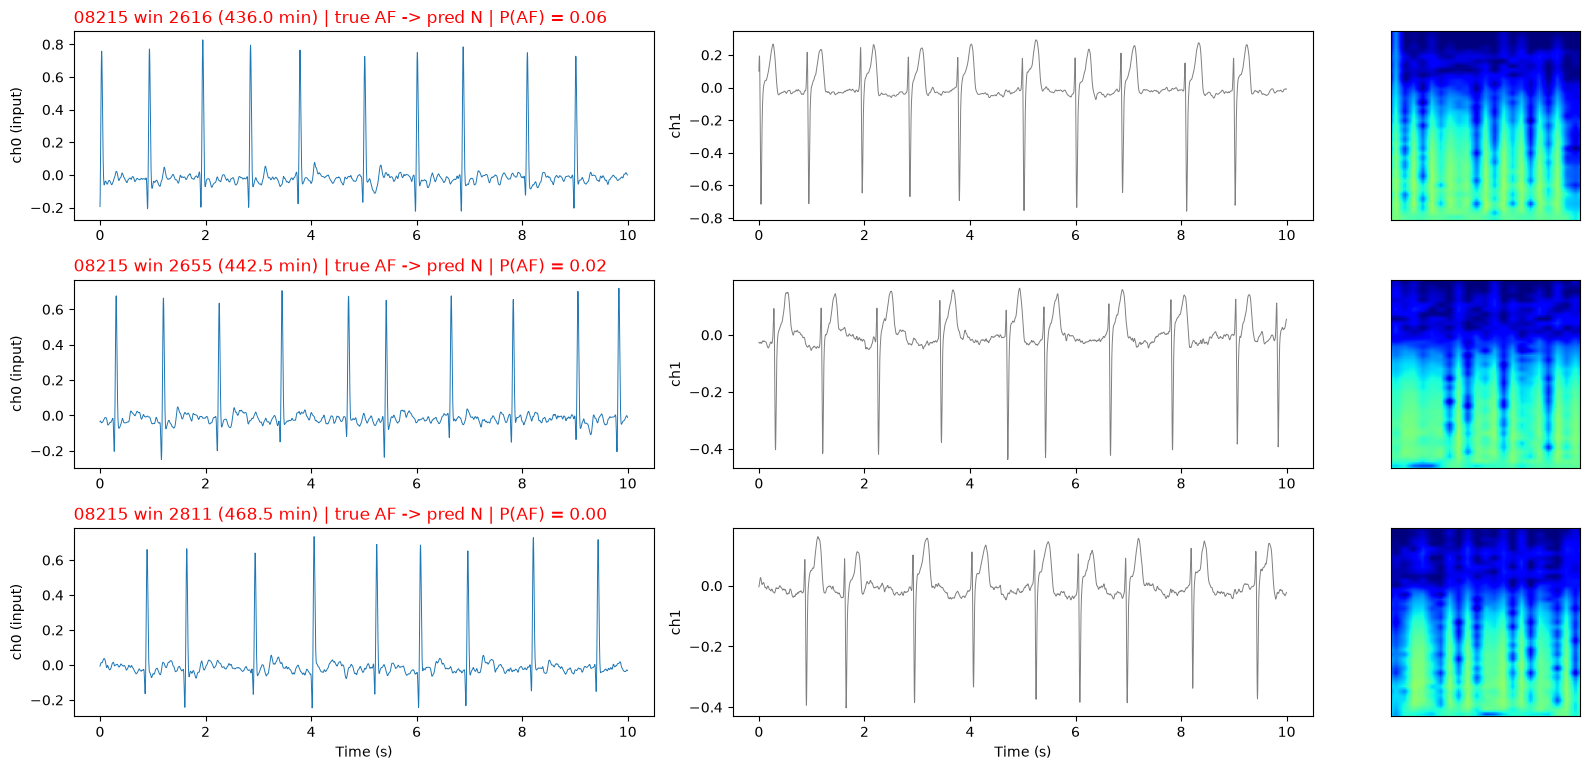

Correct, same true class:


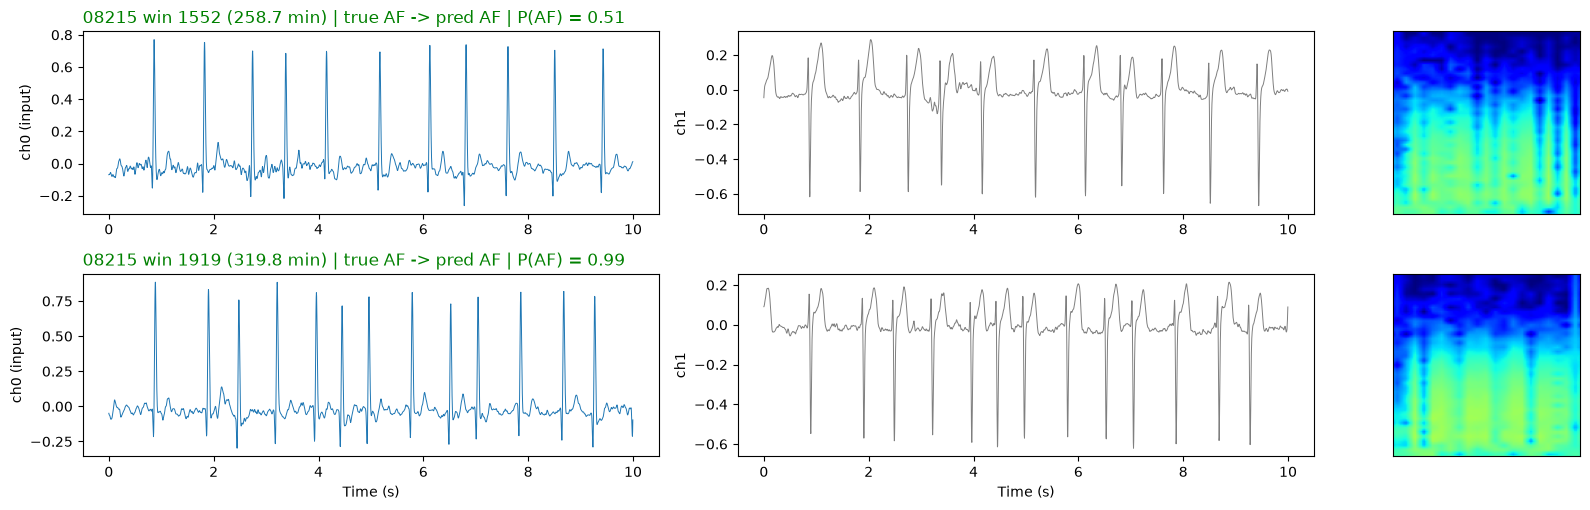


######## Fold 4: 04936 ########
Longest error runs (first, last, length): [(1098, 1117, 20), (2073, 2090, 18), (976, 991, 16)]


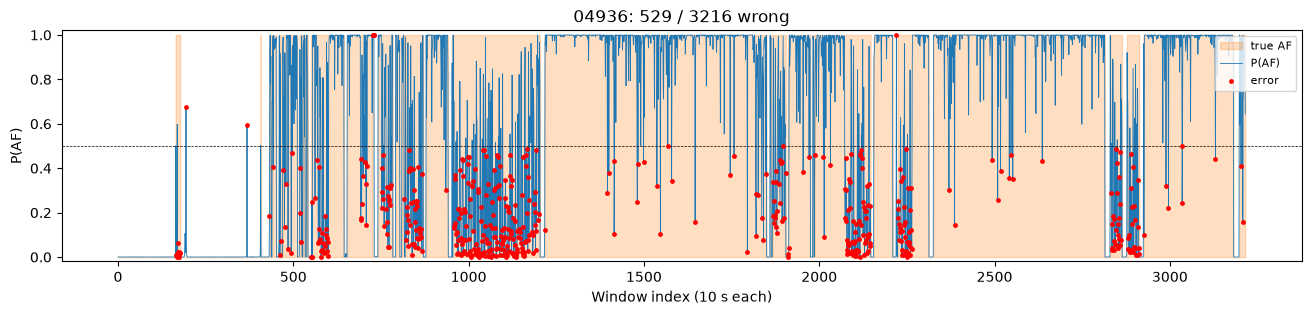

Misclassified:


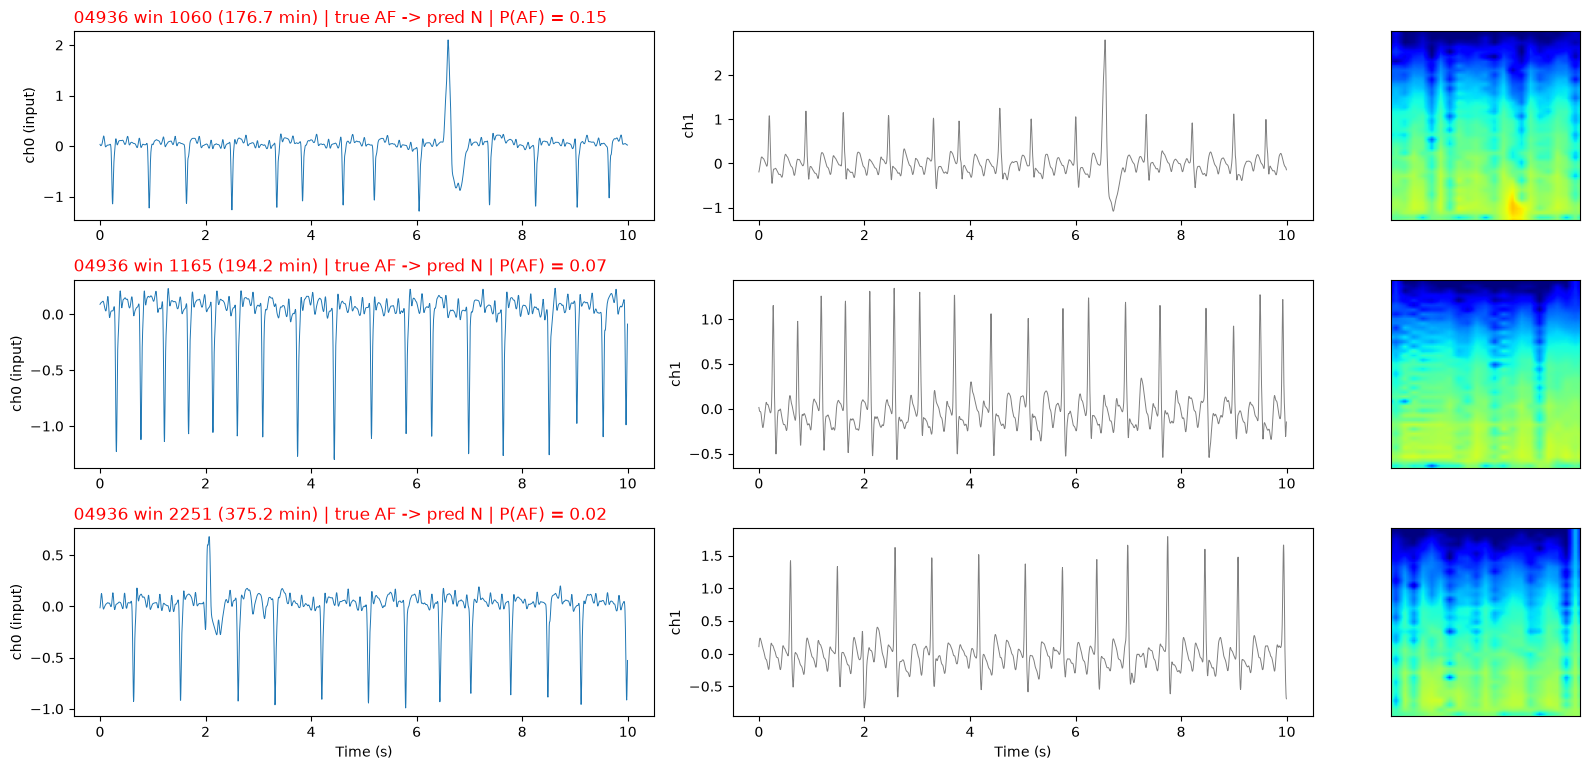

Correct, same true class:


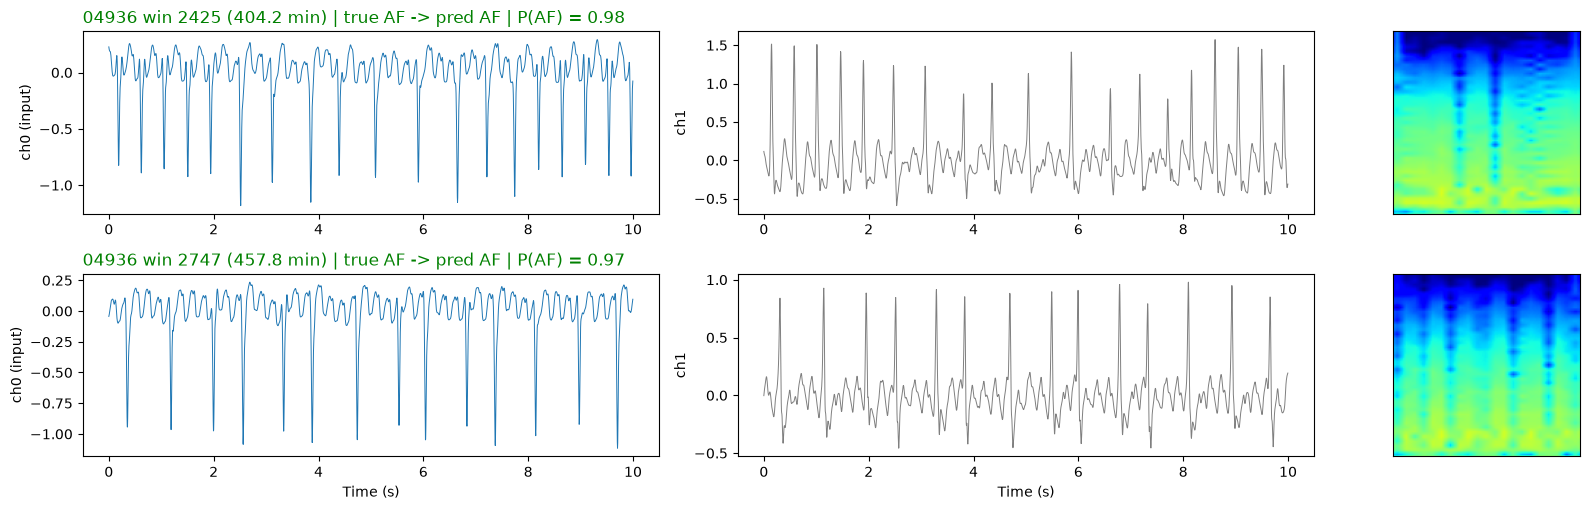


######## Fold 5: 07162 ########
Longest error runs (first, last, length): [(921, 934, 14), (1268, 1281, 14), (760, 772, 13)]


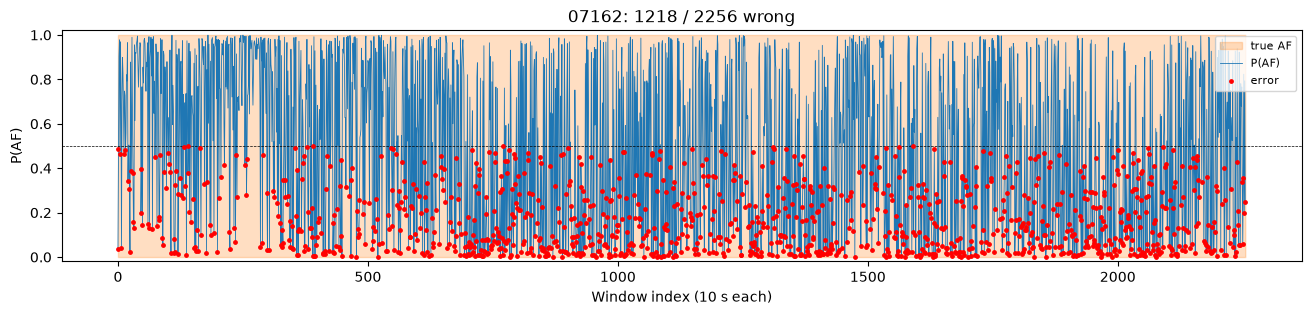

Misclassified:


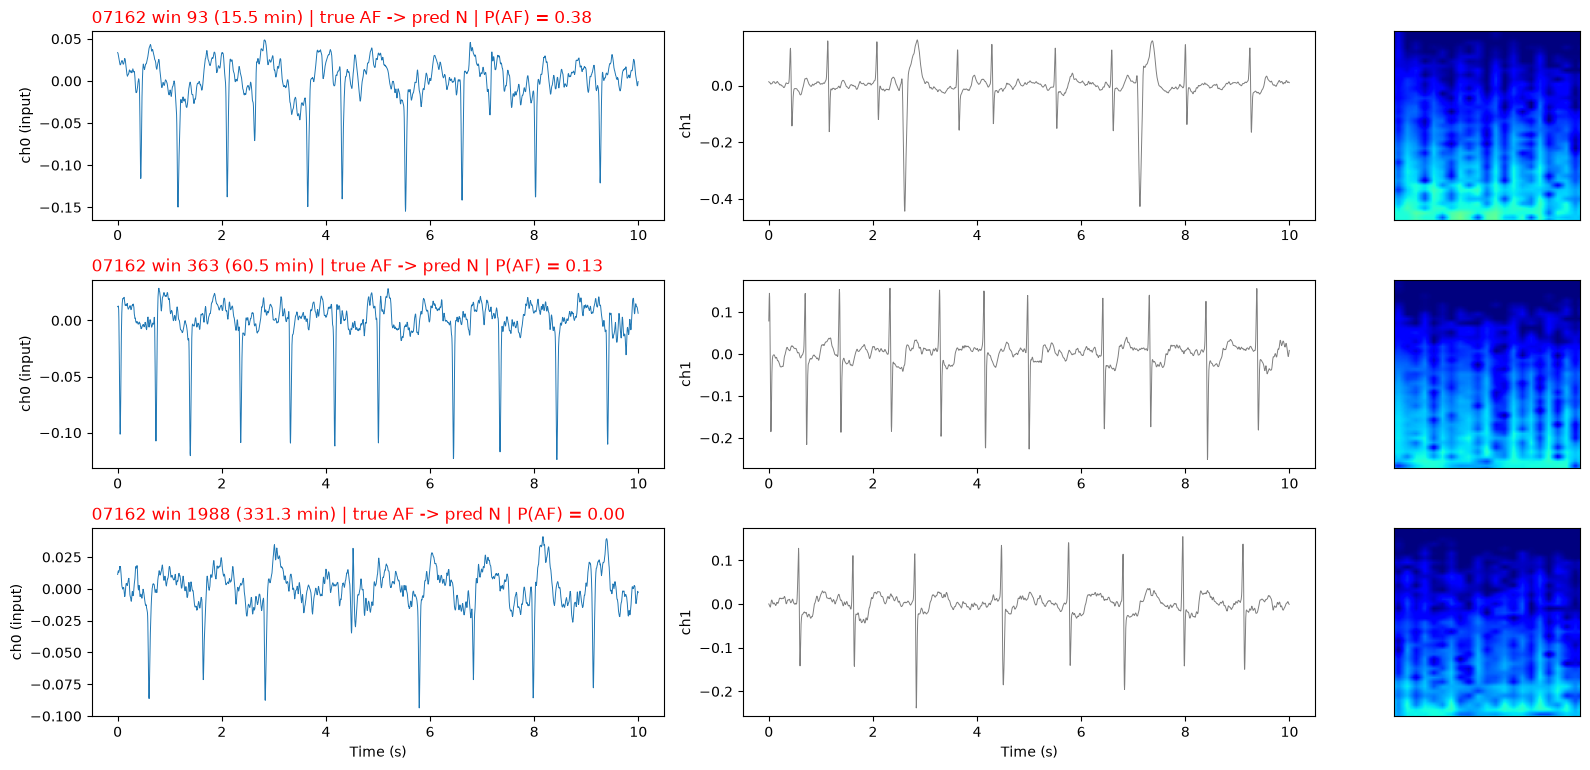

Correct, same true class:


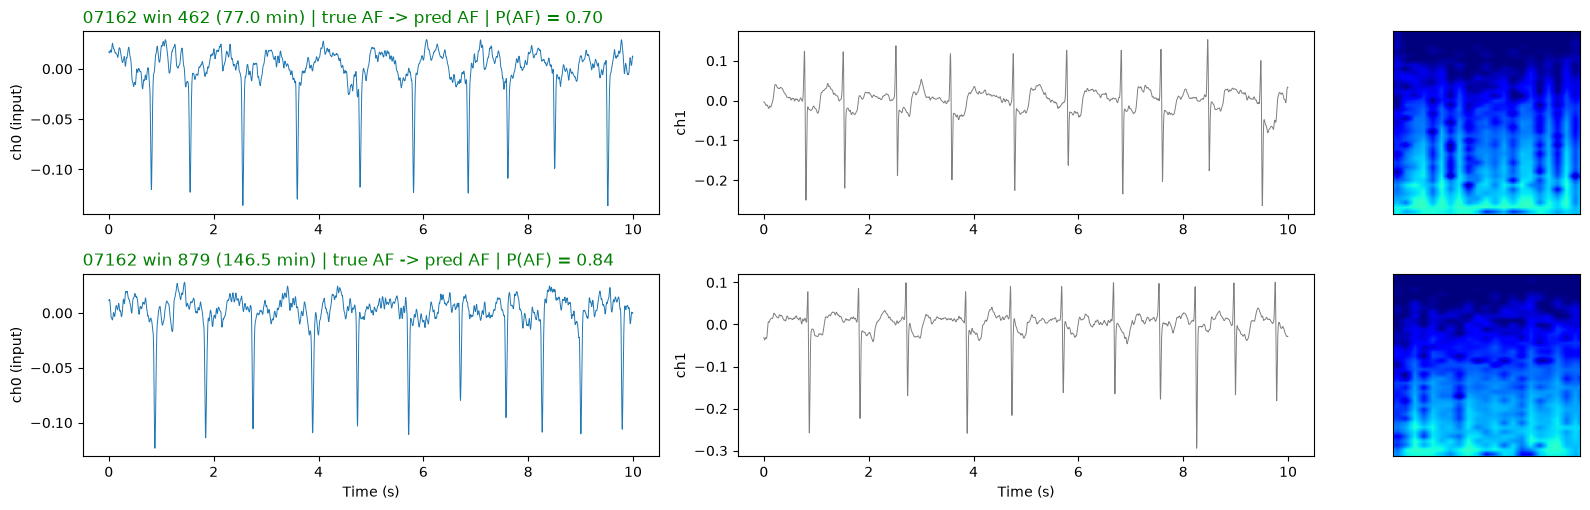

In [ ]:
rng = np.random.default_rng(0)

def pick(d, k):
    return sorted(rng.choice(d["win"].values, size = min(k, len(d)), replace = False))

for f, df in folds.items():
    rec = worst[f]
    d = df[df["rec"] == rec]
    print(f"\n######## Fold {f}: {rec} ########")
    print("Longest error runs (first, last, length):", error_runs(df, rec))
    plot_timeline(df, rec)

    wrong = d[d["err"]]
    right = d[~d["err"] & d["y"].isin(wrong["y"].unique())]
    print("Misclassified:")
    plot_windows(df, rec, pick(wrong, 3))
    print("Correct, same true class:")
    plot_windows(df, rec, pick(right, 2))

## Longest error runs

Windows from the start, middle and end of each record's longest stretch of consecutive errors.


######## Fold 2: 06995, windows 2274-2354 ########


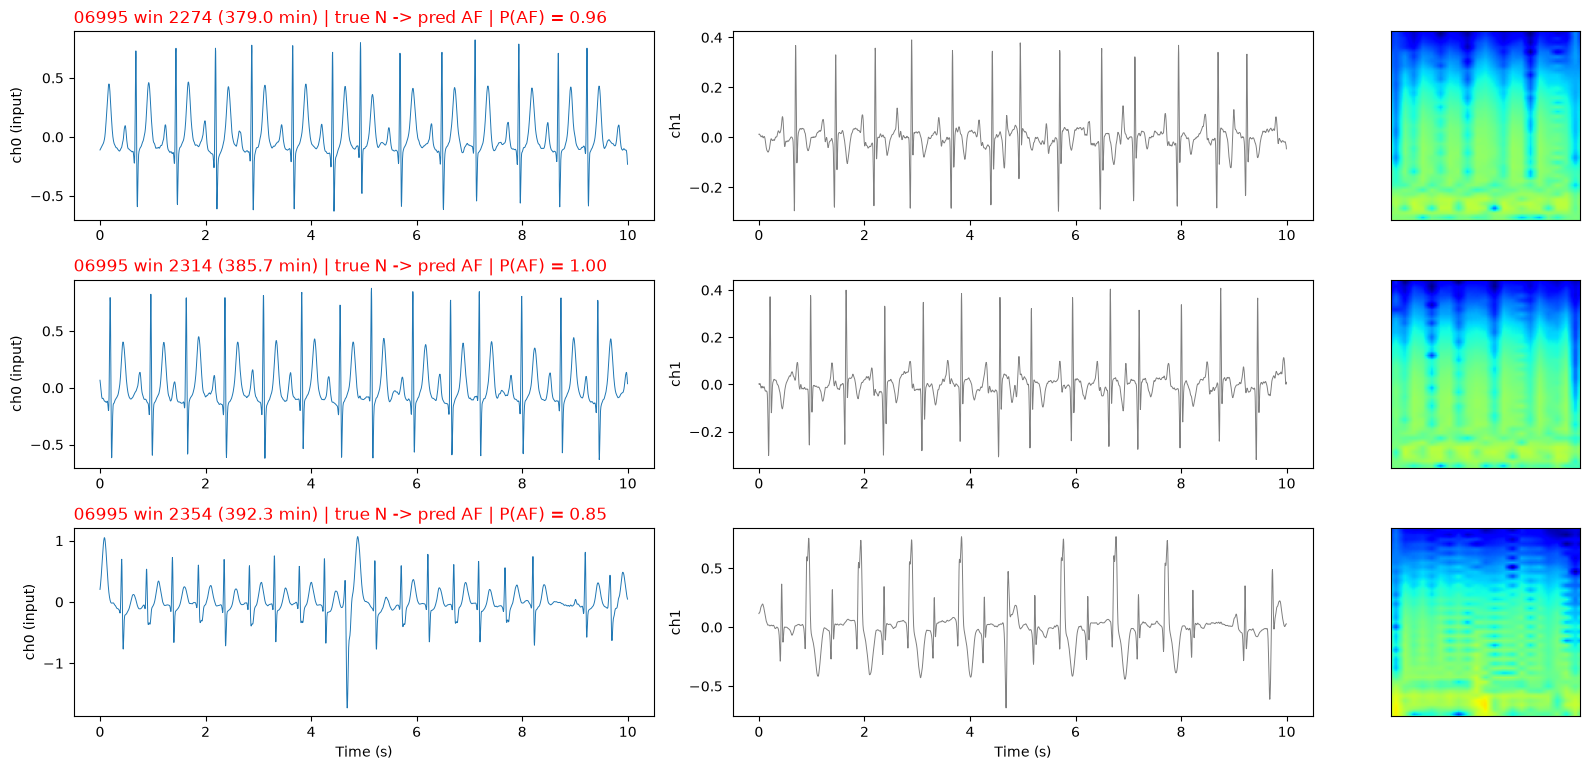


######## Fold 2: 07859, windows 1197-1220 ########


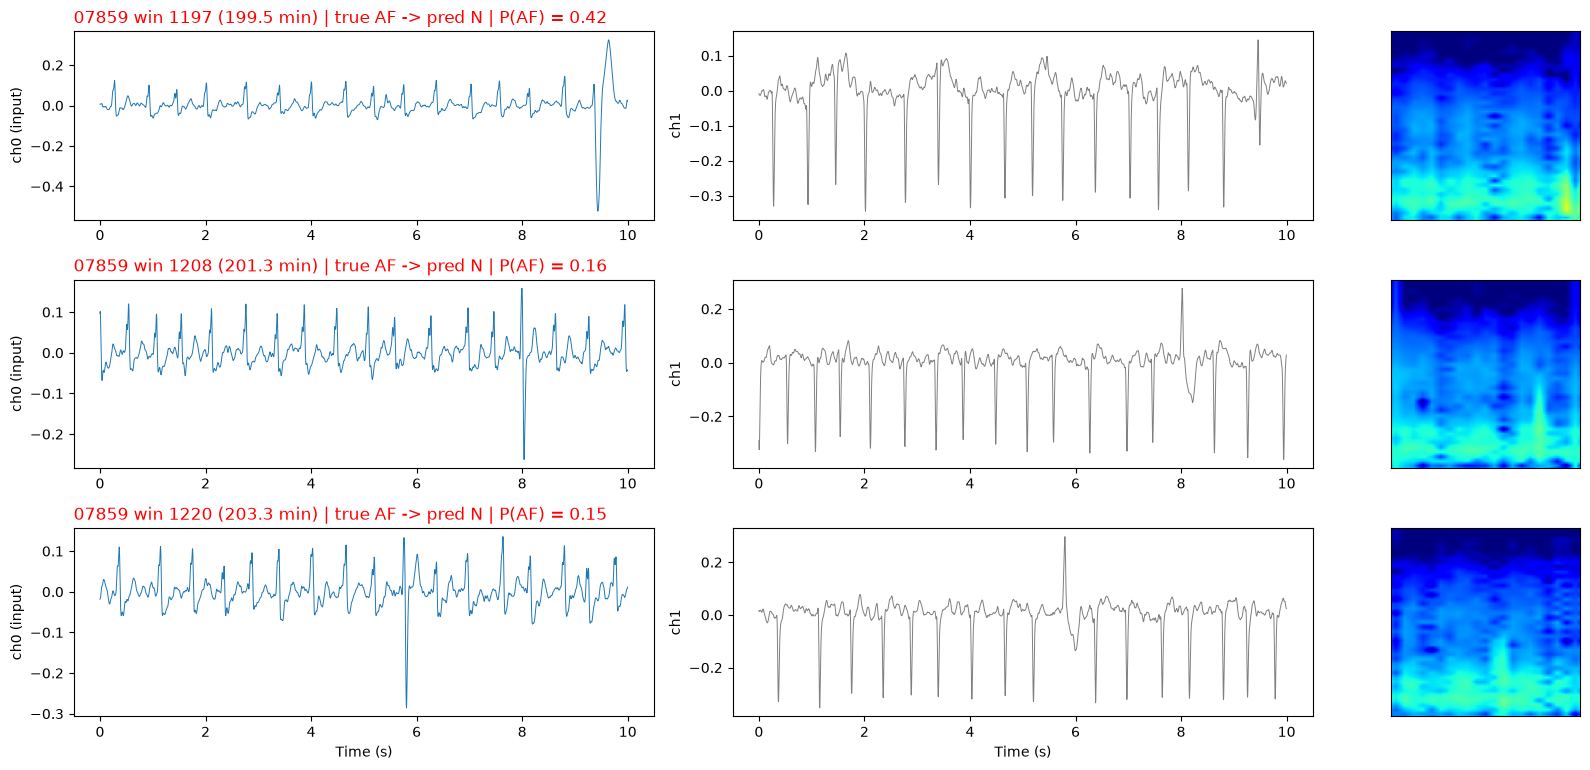


######## Fold 3: 08215, windows 2366-2455 ########


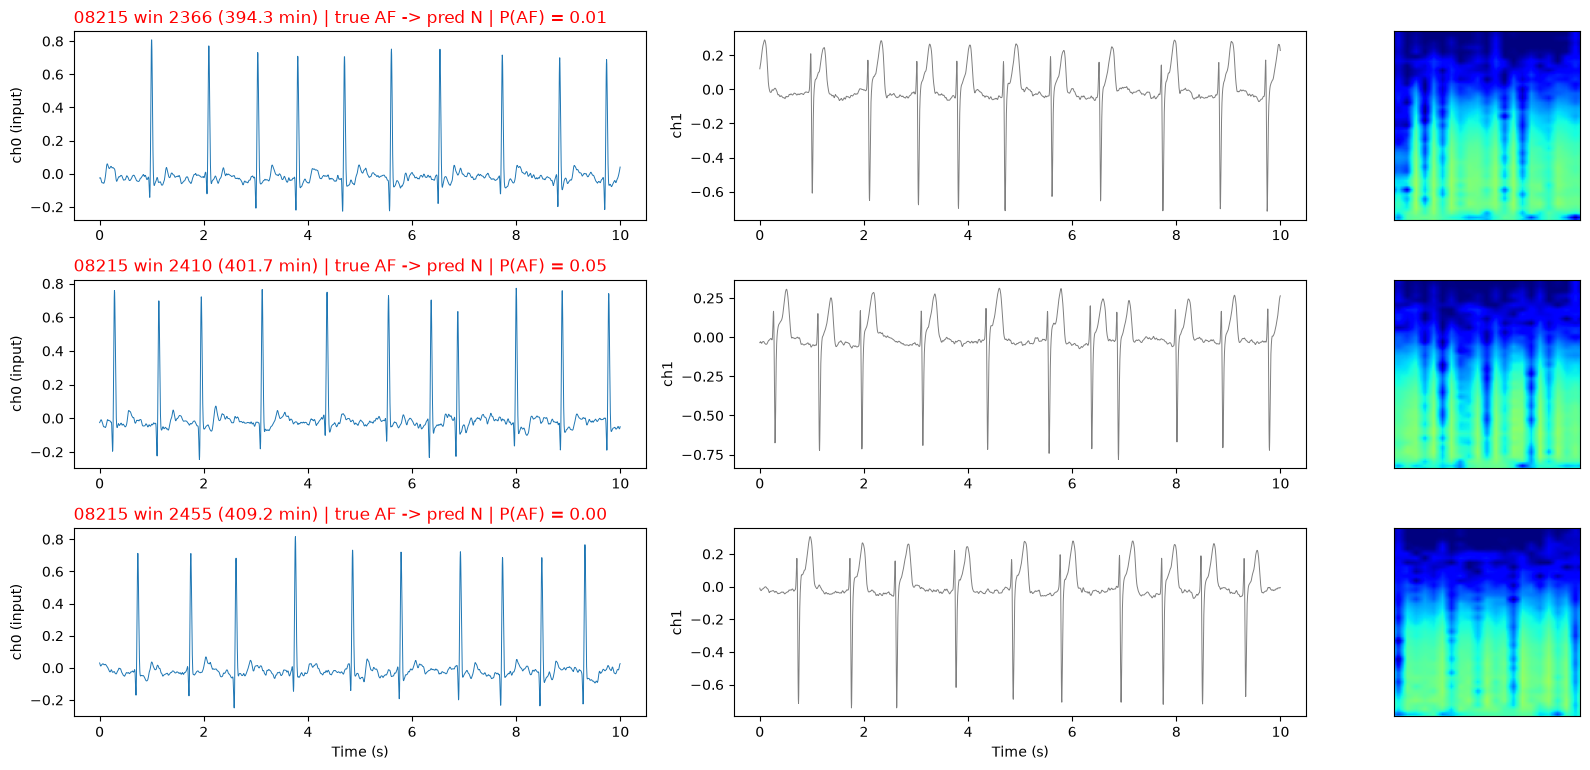


######## Fold 4: 04936, windows 1098-1117 ########


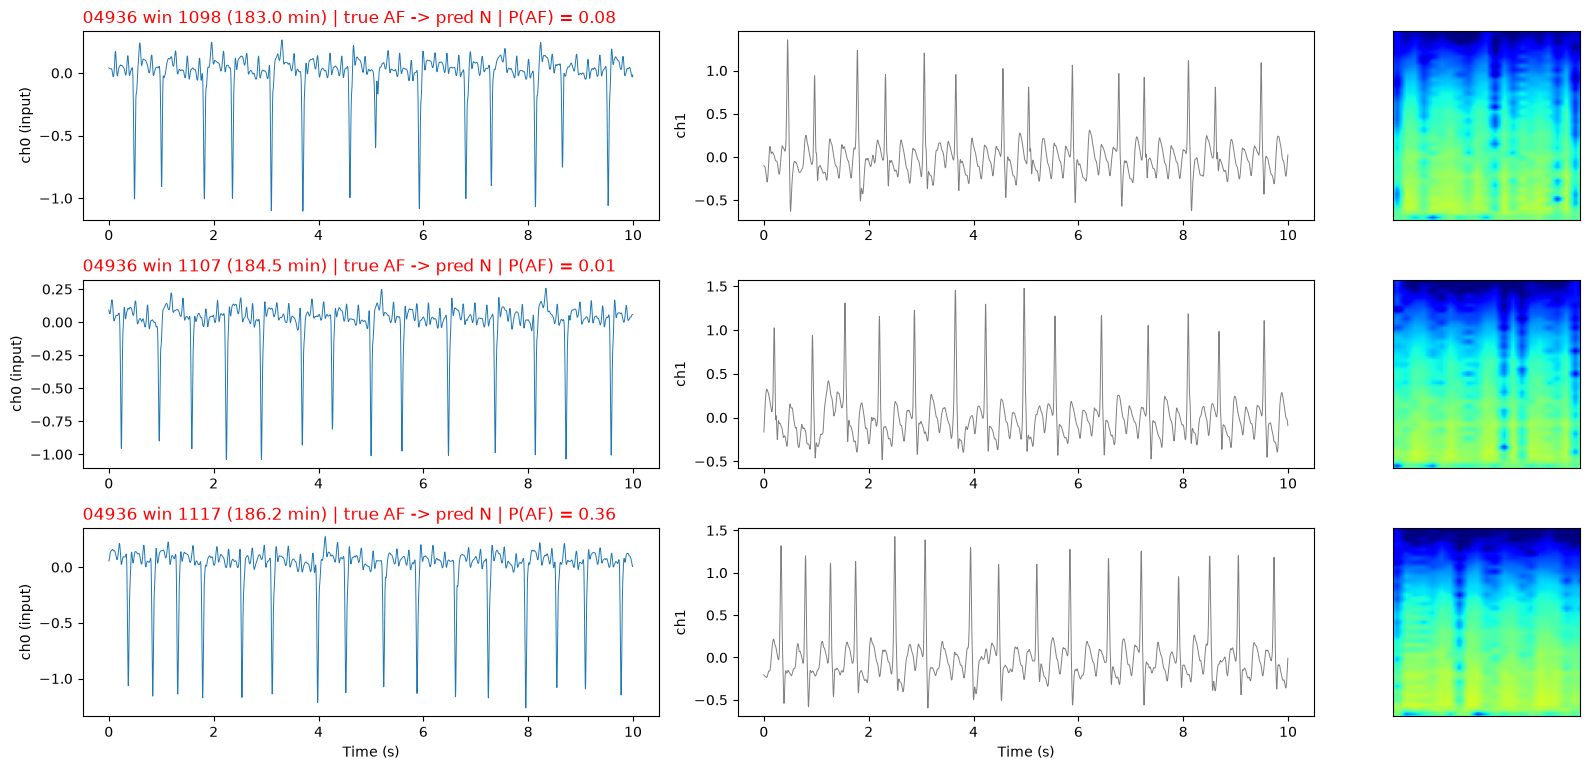


######## Fold 5: 07162, windows 921-934 ########


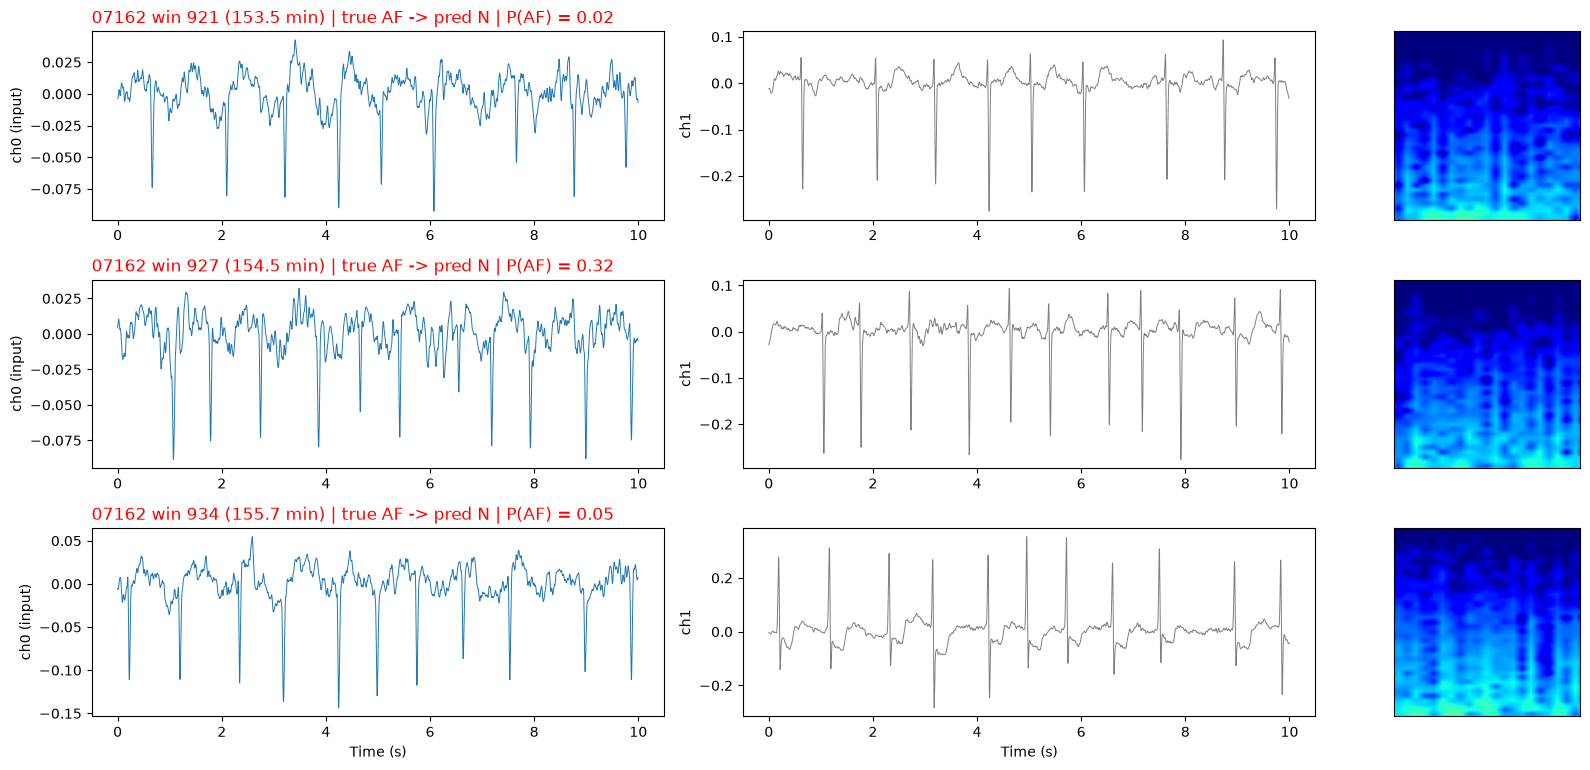

In [ ]:
for f, rec in [(2, "06995"), (2, "07859"), (3, "08215"), (4, "04936"), (5, "07162")]:
    first, last, _ = error_runs(folds[f], rec, top = 1)[0]
    print(f"\n######## Fold {f}: {rec}, windows {first}-{last} ########")
    plot_windows(folds[f], rec, [first, (first + last) // 2, last])

## Any record

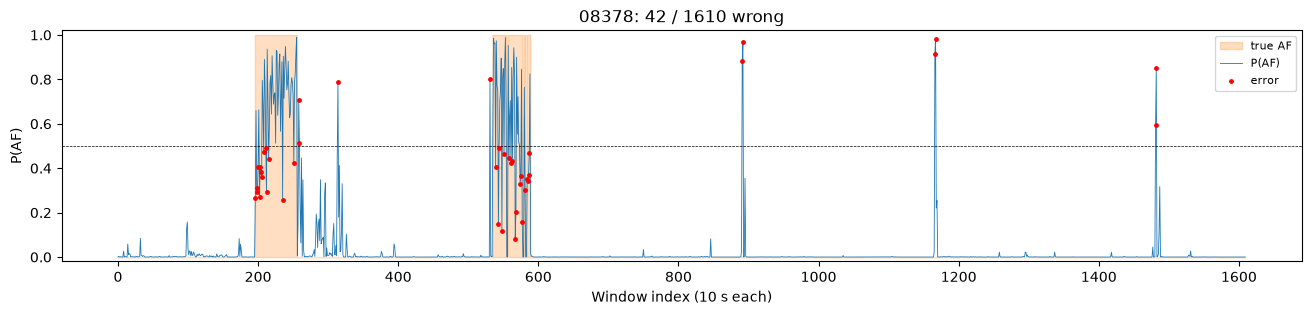

Longest error runs: [(202, 205, 4), (584, 587, 4), (198, 200, 3)]


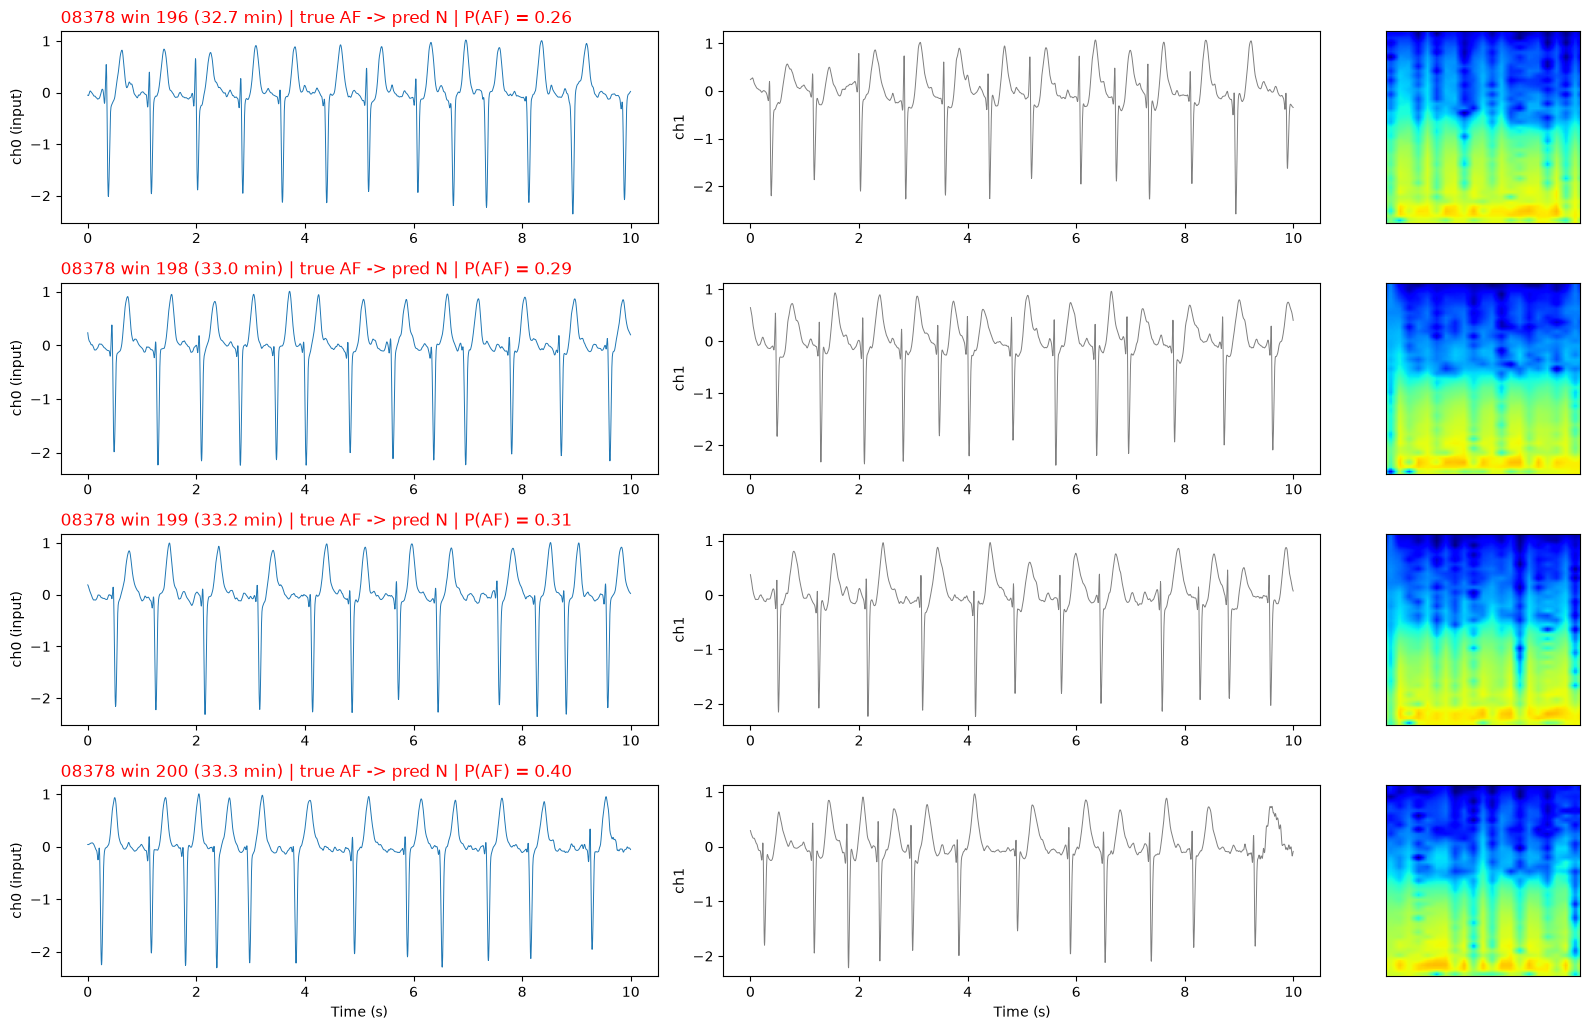

In [ ]:
# Change these to look at any record in any fold
fold, rec = 1, "08378"
plot_timeline(folds[fold], rec)
print("Longest error runs:", error_runs(folds[fold], rec))
plot_windows(folds[fold], rec, sorted(folds[fold].loc[(folds[fold]["rec"] == rec) & folds[fold]["err"], "win"].head(4)))

## Error browser

Click through the misclassified windows. Choose a fold, a record (or all records in the fold) and the error type, then use Prev / Next or the slider.

Each window shows the P(AF) timeline of its record (black line = this window), both stored channels, and the STFT image the model sees. Channel 0 is the model input: ECG1 (lead 1) in most records, ECG2 (lead 2) in the 9 swapped records. Window indices count 10 s windows from the record's first annotation, not from the start of the recording.

In [ ]:
import ipywidgets as widgets
from IPython.display import clear_output

ERROR_TYPES = {"All errors": None, "Missed AF (FN)": 1, "False AF (FP)": 0}


def lead_names(rec):
    """AFDB lead stored in (ch0, ch1). In the swapped records ch0 holds ECG2."""
    return ("ECG2", "ECG1") if rec in SWAPPED else ("ECG1", "ECG2")


def plot_error_window(fold, r):
    """One misclassified window: record timeline, both leads, and the model's STFT image."""
    df = folds[fold]
    d = df[df["rec"] == r.rec]
    seg = load_segments(r.rec)[r.win]
    lead0, lead1 = lead_names(r.rec)
    t = np.arange(len(seg)) / FS

    fig = plt.figure(figsize = (16, 7.5))
    gs = fig.add_gridspec(3, 2, width_ratios = [5, 1.3], height_ratios = [1, 1.4, 1.4])

    ax_tl = fig.add_subplot(gs[0, :])
    ax_tl.fill_between(d["win"], 0, d["y"], step = "mid", color = "tab:orange", alpha = 0.25, label = "true AF")
    ax_tl.plot(d["win"], d["p_af"], lw = 0.5, color = "tab:blue", label = "P(AF)")
    ax_tl.scatter(d.loc[d["err"], "win"], d.loc[d["err"], "p_af"], s = 3, color = "red", label = "error", zorder = 3)
    ax_tl.axvline(r.win, color = "k", lw = 1.2)
    ax_tl.axhline(0.5, ls = "--", color = "k", lw = 0.5)
    ax_tl.set(xlim = (d["win"].min(), d["win"].max()), ylim = (-0.02, 1.02), ylabel = "P(AF)",
              xlabel = f"Window index in record {r.rec} (black line = this window)")
    ax_tl.legend(loc = "upper right", fontsize = 7, ncol = 3)

    ax0 = fig.add_subplot(gs[1, 0])
    ax0.plot(t, seg[:, 0], lw = 0.7)
    ax0.set_ylabel(f"ch0 = {lead0}\n(model input)")
    ax1 = fig.add_subplot(gs[2, 0], sharex = ax0)
    ax1.plot(t, seg[:, 1], lw = 0.7, color = "tab:gray")
    ax1.set(ylabel = f"ch1 = {lead1}\n(not used)", xlabel = "Time (s)", xlim = (0, t[-1]))

    ax_im = fig.add_subplot(gs[1:, 1])
    ax_im.imshow(AFDataset._generate_image(None, seg), origin = "lower", aspect = "auto", extent = [0, 10, 0, 40])
    ax_im.set(title = f"STFT of ch0 ({lead0})", xlabel = "Time (s)", ylabel = "Hz")

    kind = "Missed AF (FN)" if r.y == 1 else "False AF (FP)"
    fig.suptitle(f"Fold {fold} | Record {r.rec} | window {r.win} | true {LABELS[r.y]} -> pred {LABELS[r.pred]} "
                 f"| P(AF) = {r.p_af:.2f} | {kind} | model sees lead {lead0[-1]} ({lead0})"
                 + (" [channels swapped]" if r.rec in SWAPPED else ""),
                 x = 0.01, ha = "left", color = "red", fontsize = 12)
    plt.tight_layout()
    plt.show()


fold_dd = widgets.Dropdown(options = [(f"Fold {f} ({d['err'].sum()} errors)", f) for f, d in folds.items()],
                           description = "Fold")
rec_dd = widgets.Dropdown(description = "Record", layout = widgets.Layout(width = "340px"))
type_tb = widgets.ToggleButtons(options = list(ERROR_TYPES), description = "Show")
prev_b = widgets.Button(description = "◀ Prev")
next_b = widgets.Button(description = "Next ▶")
idx_sl = widgets.IntSlider(min = 0, max = 0, description = "Error", continuous_update = False,
                           layout = widgets.Layout(width = "500px"))
info = widgets.HTML()
out = widgets.Output()
state = {"busy": False}   # stops a redraw for every widget change while the controls are being reset


def current_errors():
    d = folds[fold_dd.value]
    d = d[d["err"]]
    if rec_dd.value is not None:
        d = d[d["rec"] == rec_dd.value]
    t = ERROR_TYPES[type_tb.value]
    if t is not None:
        d = d[d["y"] == t]
    return d.reset_index(drop = True)


def draw(*_):
    if state["busy"]:
        return
    errs = current_errors()
    info.value = f"<b>{idx_sl.value + 1 if len(errs) else 0} / {len(errs)}</b>"
    with out:
        clear_output(wait = True)
        if len(errs) == 0:
            print("No misclassified windows for this selection.")
            return
        plot_error_window(fold_dd.value, errs.iloc[idx_sl.value])


def reset_slider(*_):
    state["busy"] = True
    idx_sl.max = max(len(current_errors()) - 1, 0)
    idx_sl.value = 0
    state["busy"] = False
    draw()


def update_records(*_):
    counts = folds[fold_dd.value].groupby("rec")["err"].sum().sort_values(ascending = False)
    state["busy"] = True
    rec_dd.options = [(f"All records ({counts.sum()} errors)", None)] + \
                     [(f"{rec}: {n} errors, ch0 = {lead_names(rec)[0]}", rec) for rec, n in counts.items() if n > 0]
    rec_dd.value = None
    state["busy"] = False
    reset_slider()


def step(k):
    n = idx_sl.max + 1
    idx_sl.value = (idx_sl.value + k) % n


prev_b.on_click(lambda _: step(-1))
next_b.on_click(lambda _: step(1))
fold_dd.observe(update_records, "value")
rec_dd.observe(reset_slider, "value")
type_tb.observe(reset_slider, "value")
idx_sl.observe(draw, "value")

display(widgets.VBox([widgets.HBox([fold_dd, rec_dd]), type_tb,
                      widgets.HBox([prev_b, next_b, idx_sl, info]), out]))
update_records()

## Record 04936 (fold 4): authcopy vs AFDB-only

04936 is 80% AF (2,563 / 3,216 windows) and holds most of fold 4's errors in both runs: 529 / 612 for `_authcopy` and 711 / 851 for `_afdb_only`, nearly all missed AF. The raw annotations also contain about 0.9 h of AFL, but no AFL windows survive segmentation, because only windows that are entirely N or entirely AF are kept. The P(AF) timelines show whether both models fail in the same places. Below them: windows from the AFDB-only model's longest error runs, then correctly classified AF windows for comparison.


######## authcopy ########
Longest error runs (first, last, length): [(1098, 1117, 20), (2073, 2090, 18), (976, 991, 16)]


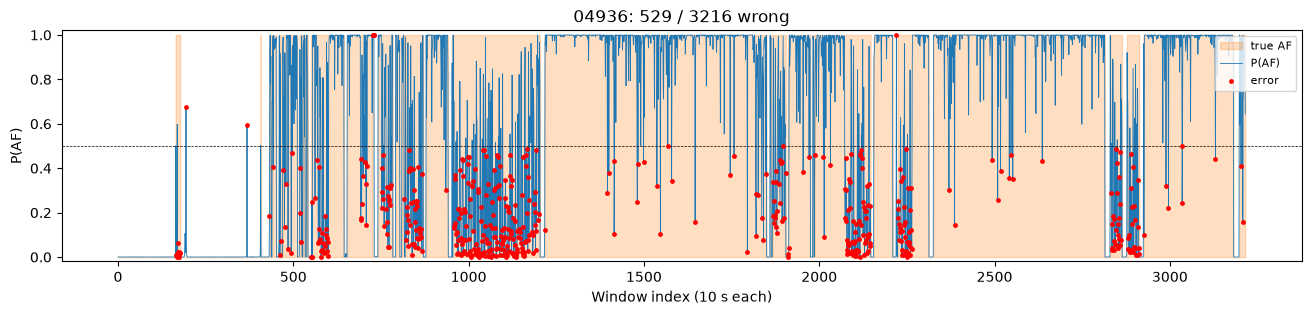


######## afdb_only ########
Longest error runs (first, last, length): [(1099, 1110, 12), (2119, 2129, 11), (2253, 2261, 9)]


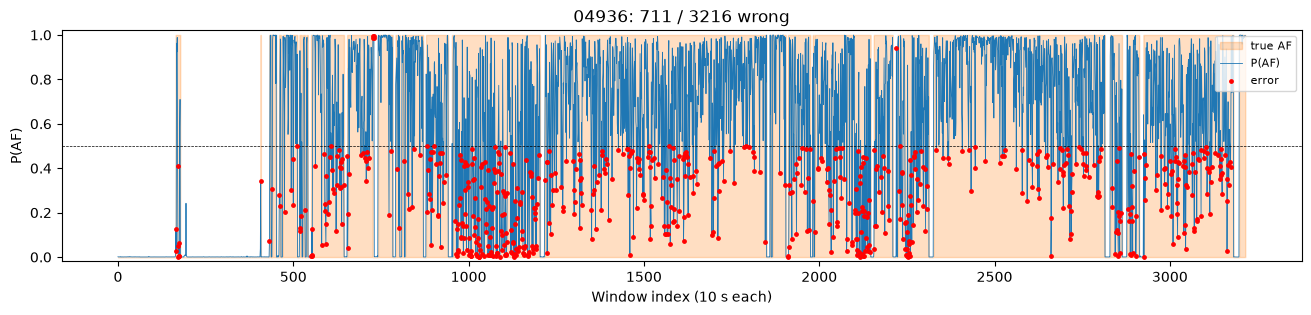


AFDB-only error run, windows 1099-1110 (12 windows):


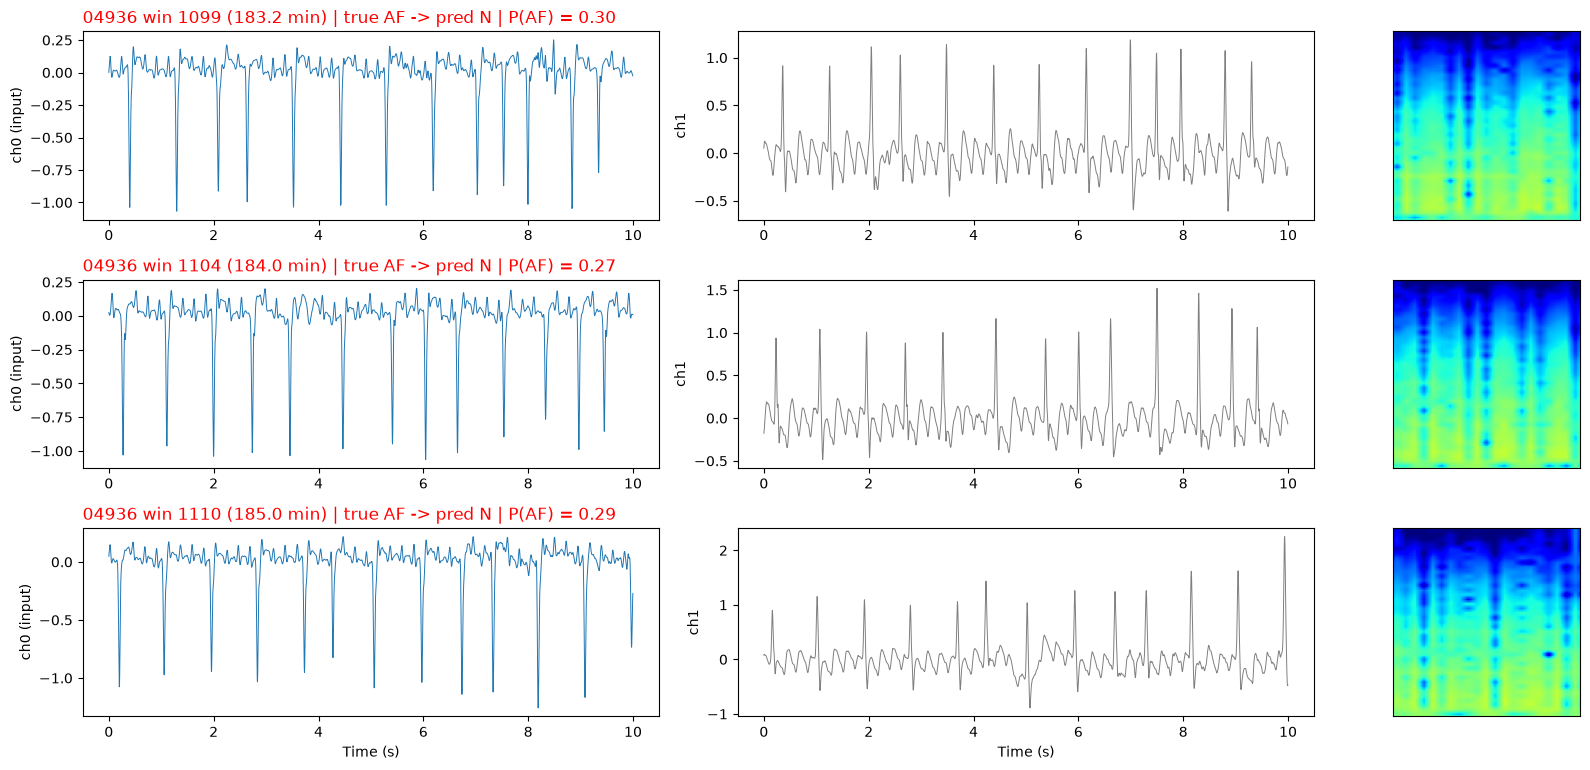


AFDB-only error run, windows 2119-2129 (11 windows):


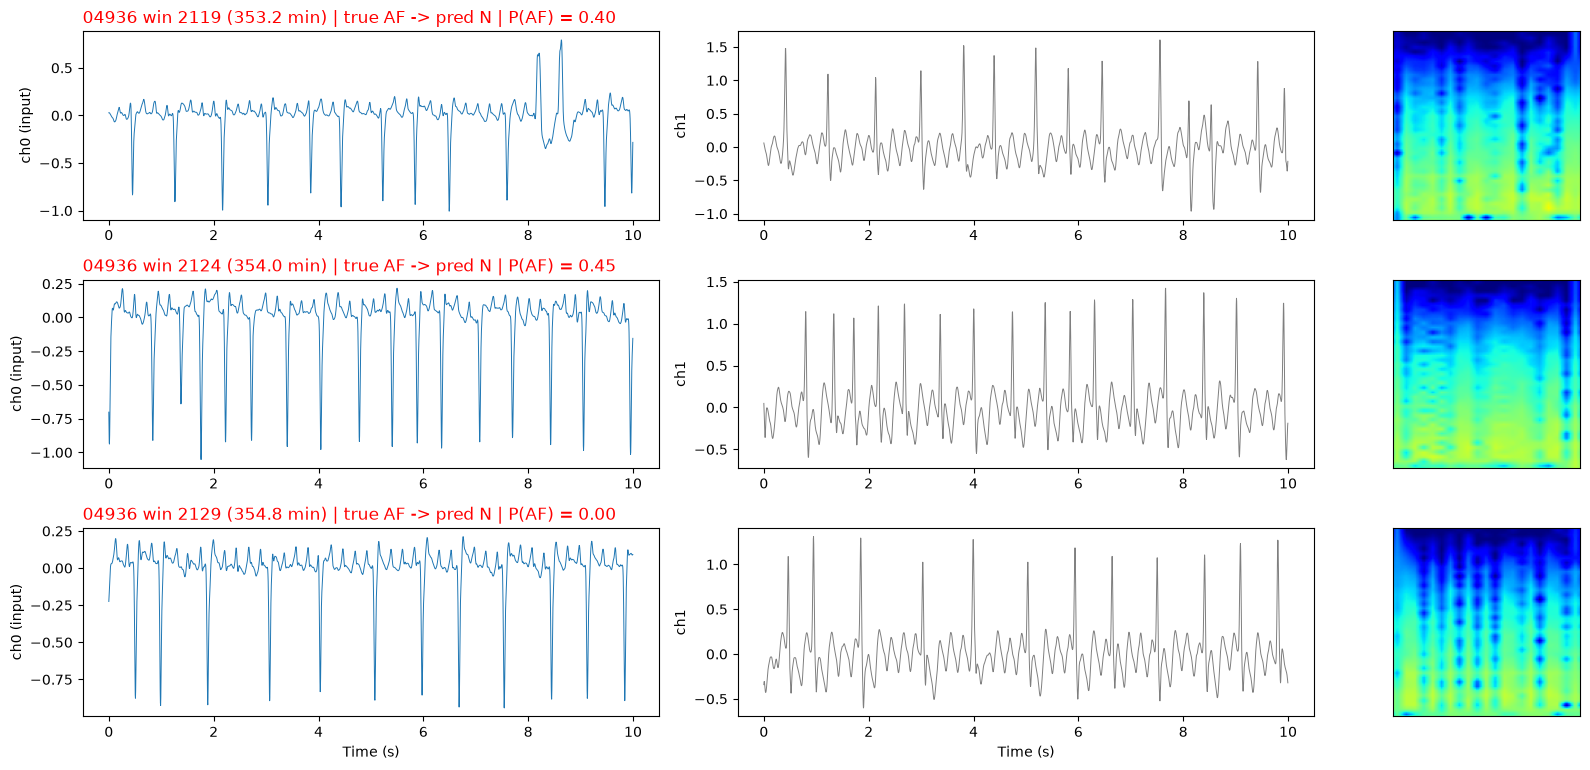

Correct AF, AFDB-only:


NameError: name 'pick' is not defined

In [5]:
rec = "04936"
runs_4936 = {"authcopy": folds[4], "afdb_only": load_fold(4, run = "afdb_only")}

for run, df in runs_4936.items():
    print(f"\n######## {run} ########")
    print("Longest error runs (first, last, length):", error_runs(df, rec))
    plot_timeline(df, rec)

df = runs_4936["afdb_only"]
for first, last, n in error_runs(df, rec, top = 2):
    print(f"\nAFDB-only error run, windows {first}-{last} ({n} windows):")
    plot_windows(df, rec, [first, (first + last) // 2, last])

d = df[df["rec"] == rec]
print("Correct AF, AFDB-only:")
plot_windows(df, rec, pick(d[~d["err"] & (d["y"] == 1)], 3))